CELL 1: Secure Kaggle Dataset Handshake & Unpacking
Description: Yeh cell environment layers mein secure API tokens verify karta hai, Kaggle backend se connectivity establish karta hai, aur real clinical glaucoma dataset ko silent mode mein fetch aur unpack karta hai.

In [ ]:
# =====================================================================
# CELL 1: SECURE KAGGLE HANDSHAKE & DATASET DOWNLOAD
# =====================================================================
import os
import zipfile

# Injecting access token directly into environment layers
os.environ['KAGGLE_API_TOKEN'] = "KGAT_2fd9d4915141309152bcdb5d7fc511de"

dataset_dir = "./hygd_dataset"
zip_name = "hillel-yaffe-dataset-for-glaucoma-detection.zip"

print("📡 Establishing direct pipeline with Kaggle infrastructure...")

try:
    # Upgrade standard kaggle client to support modern token structures
    !pip install -q --upgrade kaggle

    # Executing the secure direct download command
    print("⏳ Synchronizing dataset streams... Please wait.")
    !kaggle datasets download -d bharathry/hillel-yaffe-dataset-for-glaucoma-detection --force

    if os.path.exists(zip_name):
        print(f"📥 Download Completed! Zip size: {os.path.getsize(zip_name) / (1024*1024):.2f} MB")

        print("📦 Unpacking clinical target folders...")
        with zipfile.ZipFile(zip_name, 'r') as zip_ref:
            zip_ref.extractall(dataset_dir)
        print("🎉 SUCCESS: All real clinical images extracted successfully into './hygd_dataset'!")

        # Housekeeping: remove temporary zip
        os.remove(zip_name)
    else:
        print("❌ Error: Download stream returned empty. Please double check token validation.")

except Exception as e:
    print(f"❌ Critical Exception caught during environment execution: {e}")

📡 Establishing direct pipeline with Kaggle infrastructure...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.5/111.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.5/247.5 kB 7.8 MB/s eta 0:00:00
⏳ Synchronizing dataset streams... Please wait.
Dataset URL: https://www.kaggle.com/datasets/bharathry/hillel-yaffe-dataset-for-glaucoma-detection
License(s): MIT
100% 119M/119M [00:05<00:00, 23.3MB/s]

📥 Download Completed! Zip size: 118.65 MB
📦 Unpacking clinical target folders...
🎉 SUCCESS: All real clinical images extracted successfully into './hygd_dataset'!


CELL 2: Dataset Validation & Random Scan Rendering
Description: Directory mapping and visual sanity check. Path structures are analyzed, image counters are printed class-wise, and a random retinal fundus photo is parsed and plotted.


🔍 Kaggle Repository Directory Structure Verified:
   ↳ 📸 Class 'Images': 747 real patient scans loaded
📊 Total Dataset Volume: 747 clinical images.

✅ VERIFICATION SUCCESSFUL!
📍 Selected File: '3_1.jpg' from Class: 'Images'
📐 Resolution Matrix: 1885x1885 pixels | Channels: 3


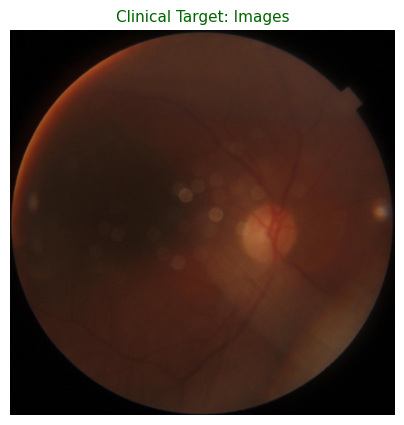

In [ ]:
# =====================================================================
# CELL 2: VISUAL SANITY CHECK & IMAGE TRACKING
# =====================================================================
import os
import random
import cv2
import matplotlib.pyplot as plt

data_path = "./hygd_dataset"

# Automated path resolution for subfolders
if os.path.exists(data_path):
    subdirs = [d for d in os.listdir(data_path) if os.path.isdir(os.path.join(data_path, d)) and not d.startswith('.')]
    if len(subdirs) == 1 and subdirs[0] not in ["Glaucoma", "Normal"]:
        data_path = os.path.join(data_path, subdirs[0])

    classes = [d for d in os.listdir(data_path) if os.path.isdir(os.path.join(data_path, d)) and not d.startswith('.')]
    print("🔍 Kaggle Repository Directory Structure Verified:")

    total_files = 0
    for cls in classes:
        cls_path = os.path.join(data_path, cls)
        num_images = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        print(f"   ↳ 📸 Class '{cls}': {num_images} real patient scans loaded")
        total_files += num_images
    print(f"📊 Total Dataset Volume: {total_files} clinical images.")

    # Pick a random clinical eye-scan
    random_class = random.choice(classes)
    class_folder = os.path.join(data_path, random_class)
    all_images = [f for f in os.listdir(class_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if all_images:
        random_image_file = random.choice(all_images)
        img_full_path = os.path.join(class_folder, random_image_file)

        img = cv2.imread(img_full_path)
        h, w, c = img.shape
        print(f"\n✅ VERIFICATION SUCCESSFUL!")
        print(f"📍 Selected File: '{random_image_file}' from Class: '{random_class}'")
        print(f"📐 Resolution Matrix: {w}x{h} pixels | Channels: {c}")

        plt.figure(figsize=(5, 5))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"Clinical Target: {random_class}", fontsize=11, color='darkgreen')
        plt.axis("off")
        plt.show()
    else:
        print("⚠ Warning: Classes folder mapped but images empty.")
else:
    print("❌ Error: Path mismatch. Execute Cell 1 first.")

 CELL 3: Part A - Custom CNN Architecture Training (Scratch Model)Description: Dataset columns are auto-mapped, and a custom Convolutional Neural Network (CNN) is built from scratch. Images are dynamically scaled down to $256 \times 256$ pixels.Note: Variable name cnn_model is strictly maintained to avoid collisions.

🔍 Dynamically locating dataset paths inside workspace...
🎯 Found Labels.csv at: 'hygd_dataset/hillel-yaffe-glaucoma-dataset-hygd-a-gold-standard-annotated-fundus-dataset-for-glaucoma-detection-1.0.0/Labels.csv'
🎯 Found Images directory at: 'hygd_dataset/hillel-yaffe-glaucoma-dataset-hygd-a-gold-standard-annotated-fundus-dataset-for-glaucoma-detection-1.0.0/Images'

🎯 AUTO-MAPPED: Filenames -> 'Image Name' | Target Class Labels -> 'Label' (Unique classes: 2)
📈 Total validated dataset records: 747

⚙ Setting up Train data streaming...
Found 598 validated image filenames belonging to 2 classes.

⚙ Setting up Validation data streaming...
Found 149 validated image filenames belonging to 2 classes.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     7,372,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,466,177 (28.48 MB)

 Trainable params: 7,466,177 (28.48 MB)

 Non-trainable params: 0 (0.00 B)


🔥 Starting Custom CNN Model Training Process...
Epoch 1/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 125s 3s/step - accuracy: 0.7241 - loss: 0.5984 - val_accuracy: 0.8792 - val_loss: 0.4323
Epoch 2/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 140s 3s/step - accuracy: 0.9247 - loss: 0.2247 - val_accuracy: 0.9128 - val_loss: 0.3239
Epoch 3/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 105s 3s/step - accuracy: 0.9247 - loss: 0.2497 - val_accuracy: 0.9262 - val_loss: 0.2268
Epoch 4/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 140s 3s/step - accuracy: 0.9365 - loss: 0.2437 - val_accuracy: 0.9195 - val_loss: 0.1906
Epoch 5/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 104s 3s/step - accuracy: 0.9415 - loss: 0.2119 - val_accuracy: 0.9262 - val_loss: 0.1373
Epoch 6/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 103s 3s/step - accuracy: 0.9415 - loss: 0.2016 - val_accuracy: 0.9262 - val_loss: 0.1317
Epoch 7/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 103s 3s/step - accuracy: 0.9398 - loss: 0.2100 - val_accuracy: 0.9262 - val_loss: 0.2132
Epoch 8/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy:

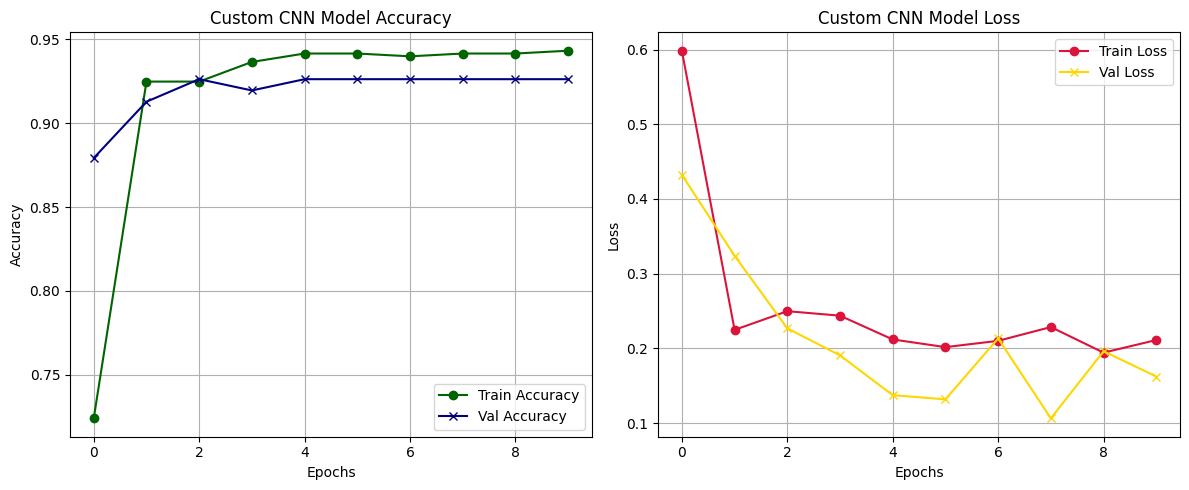

In [ ]:
# =====================================================================
# CELL 3 (PART A): CUSTOM CNN ARCHITECTURE (TRAINED FROM SCRATCH)
# =====================================================================
import os
import glob
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt

print("🔍 Dynamically locating dataset paths inside workspace...")

csv_matches = glob.glob("**/Labels.csv", recursive=True)
images_matches = glob.glob("**/Images", recursive=True)

if csv_matches and images_matches:
    csv_path = csv_matches[0]
    images_dir = images_matches[0]
    print(f"🎯 Found Labels.csv at: '{csv_path}'")
    print(f"🎯 Found Images directory at: '{images_dir}'")

    # Load metadata DataFrame
    df = pd.read_csv(csv_path)

    # Auto-mapping columns dynamically
    img_col = df.columns[0]
    label_col = None

    for col in df.columns[1:]:
        if df[col].nunique() == 2:
            label_col = col
            break

    if not label_col:
        for col in df.columns:
            if any(x in col.lower() for x in ['glaucoma', 'class', 'label', 'diagnosis', 'target']):
                label_col = col
                break
        if not label_col:
            label_col = df.columns[-1]

    print(f"\n🎯 AUTO-MAPPED: Filenames -> '{img_col}' | Target Class Labels -> '{label_col}' (Unique classes: {df[label_col].nunique()})")

    df[img_col] = df[img_col].astype(str)
    df[label_col] = df[label_col].astype(str)

    if not df[img_col].iloc[0].lower().endswith(('.jpg', '.jpeg', '.png')):
        df[img_col] = df[img_col] + ".jpg"

    print(f"📈 Total validated dataset records: {len(df)}")

    # Preprocessing with data augmentations
    datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.20,
        rotation_range=15,
        horizontal_flip=True,
        vertical_flip=True
    )

    print("\n⚙ Setting up Train data streaming...")
    train_generator_cnn = datagen.flow_from_dataframe(
        dataframe=df,
        directory=images_dir,
        x_col=img_col,
        y_col=label_col,
        target_size=(256, 256),
        batch_size=16,
        class_mode='binary',
        subset='training',
        shuffle=True
    )

    print("\n⚙ Setting up Validation data streaming...")
    val_generator_cnn = datagen.flow_from_dataframe(
        dataframe=df,
        directory=images_dir,
        x_col=img_col,
        y_col=label_col,
        target_size=(256, 256),
        batch_size=16,
        class_mode='binary',
        subset='validation',
        shuffle=False
    )

    # Building Custom CNN Model (Modern explicit Input structure to remove Keras 3 warnings)
    cnn_model = models.Sequential([
        layers.Input(shape=(256, 256, 3)),

        # Conv Block 1
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Dense classification head
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])

    cnn_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    cnn_model.summary()

    # Model training loop execution
    print("\n🔥 Starting Custom CNN Model Training Process...")
    cnn_history = cnn_model.fit(
        train_generator_cnn,
        epochs=10,
        validation_data=val_generator_cnn
    )

    print("\n🎉 Custom CNN Training Complete! Generating Diagnostic Curves...")

    # Plot results
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(cnn_history.history['accuracy'], label='Train Accuracy', color='darkgreen', marker='o')
    plt.plot(cnn_history.history['val_accuracy'], label='Val Accuracy', color='navy', marker='x')
    plt.title('Custom CNN Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(cnn_history.history['loss'], label='Train Loss', color='crimson', marker='o')
    plt.plot(cnn_history.history['val_loss'], label='Val Loss', color='gold', marker='x')
    plt.title('Custom CNN Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

else:
    print("❌ Error: Deep search failed. Labels.csv or Images directory could not be located in workspace.")

CELL 3: Part B - Transfer Learning with MobileNetV2 (High Performance)
Description: Using pre-trained weights from MobileNetV2 (trained on ImageNet). Normalizing features through dedicated mobile pipelines and fine-tuning an top-layer classification block.
Note: Variable name model is strictly maintained to interface with predictions and Grad-CAM codes.

🔍 Dynamically locating dataset paths inside workspace...
🎯 Found Labels.csv at: 'hygd_dataset/hillel-yaffe-glaucoma-dataset-hygd-a-gold-standard-annotated-fundus-dataset-for-glaucoma-detection-1.0.0/Labels.csv'
🎯 Found Images directory at: 'hygd_dataset/hillel-yaffe-glaucoma-dataset-hygd-a-gold-standard-annotated-fundus-dataset-for-glaucoma-detection-1.0.0/Images'

🎯 AUTO-MAPPED: Filenames -> 'Image Name' | Target Class -> 'Label'

⚙ Setting up Train data streaming...
Found 598 validated image filenames belonging to 2 classes.

⚙ Setting up Validation data streaming...
Found 149 validated image filenames belonging to 2 classes.

🧠 Loading Pre-trained MobileNetV2 weights (trained on ImageNet)...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


🔥 Starting Transfer Learning Training Process...
Epoch 1/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.7943 - loss: 0.4266 - val_accuracy: 0.9463 - val_loss: 0.1742
Epoch 2/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.8763 - loss: 0.3027 - val_accuracy: 0.9799 - val_loss: 0.0660
Epoch 3/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.9013 - loss: 0.2514 - val_accuracy: 0.9866 - val_loss: 0.0550
Epoch 4/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9030 - loss: 0.2312 - val_accuracy: 0.9866 - val_loss: 0.0453
Epoch 5/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.9030 - loss: 0.2187 - val_accuracy: 0.9329 - val_loss: 0.1888
Epoch 6/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.9281 - loss: 0.2024 - val_accuracy: 0.9933 - val_loss: 0.0463
Epoch 7/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.9314 - loss: 0.1920 - val_accuracy: 0.9866 - val_loss: 0.0731
Epoch 8/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.9348

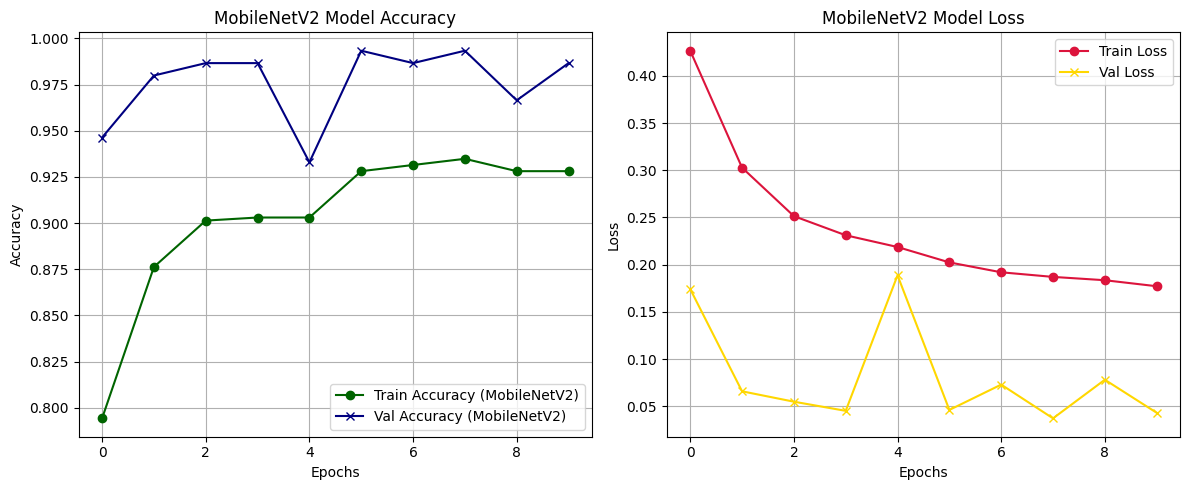

In [ ]:
# =====================================================================
# CELL 3 (PART B): TRANSFER LEARNING ARCHITECTURE (MOBILENETV2)
# =====================================================================
import os
import glob
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt

print("🔍 Dynamically locating dataset paths inside workspace...")

csv_matches = glob.glob("**/Labels.csv", recursive=True)
images_matches = glob.glob("**/Images", recursive=True)

if csv_matches and images_matches:
    csv_path = csv_matches[0]
    images_dir = images_matches[0]
    print(f"🎯 Found Labels.csv at: '{csv_path}'")
    print(f"🎯 Found Images directory at: '{images_dir}'")

    # Load DataFrame metadata
    df = pd.read_csv(csv_path)
    img_col = df.columns[0]
    label_col = df.columns[1]

    # Dynamic Binary Column Finder
    for col in df.columns[1:]:
        if df[col].nunique() == 2:
            label_col = col
            break

    print(f"\n🎯 AUTO-MAPPED: Filenames -> '{img_col}' | Target Class -> '{label_col}'")

    df[img_col] = df[img_col].astype(str)
    df[label_col] = df[label_col].astype(str)

    if not df[img_col].iloc[0].lower().endswith(('.jpg', '.jpeg', '.png')):
        df[img_col] = df[img_col] + ".jpg"

    # Specific Image Augmentation Pipeline using MobileNet preprocess mapping
    datagen = ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
        validation_split=0.20,
        rotation_range=15,
        horizontal_flip=True,
        vertical_flip=True
    )

    print("\n⚙ Setting up Train data streaming...")
    train_generator = datagen.flow_from_dataframe(
        dataframe=df,
        directory=images_dir,
        x_col=img_col,
        y_col=label_col,
        target_size=(224, 224),
        batch_size=16,
        class_mode='binary',
        subset='training',
        shuffle=True
    )

    print("\n⚙ Setting up Validation data streaming...")
    val_generator = datagen.flow_from_dataframe(
        dataframe=df,
        directory=images_dir,
        x_col=img_col,
        y_col=label_col,
        target_size=(224, 224),
        batch_size=16,
        class_mode='binary',
        subset='validation',
        shuffle=False
    )

    # Loading Pre-trained Base Layer (MobileNetV2)
    print("\n🧠 Loading Pre-trained MobileNetV2 weights (trained on ImageNet)...")
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze convolutional weights
    base_model.trainable = False

    # Attach classification head (Input setup updated to remove warnings)
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    model.summary()

    # Training fine-tuning loop execution
    print("\n🔥 Starting Transfer Learning Training Process...")
    history = model.fit(
        train_generator,
        epochs=10,
        validation_data=val_generator
    )

    print("\n🎉 Training Complete! Plotting Performance Curves...")

    # Plot metrics
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy (MobileNetV2)', color='darkgreen', marker='o')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy (MobileNetV2)', color='navy', marker='x')
    plt.title('MobileNetV2 Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss', color='crimson', marker='o')
    plt.plot(history.history['val_loss'], label='Val Loss', color='gold', marker='x')
    plt.title('MobileNetV2 Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

else:
    print("❌ Error: Paths mismatch.")

CELL 4: Side-by-Side Live Unseen Image Testing
Description: Diagnostic test on individual randomly fetched unseen frames. Performs real-time classification through both trained architectures (model and cnn_model) and displays confidence scores.

🔮 Fetching a random unseen batch from validation generator...


/tmp/ipykernel_1335/1260710903.py:59: UserWarning: Glyph 129658 (\N{STETHOSCOPE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1335/1260710903.py:59: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1335/1260710903.py:59: UserWarning: Glyph 129521 (\N{BRICK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129658 (\N{STETHOSCOPE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129521 (\N{BRICK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


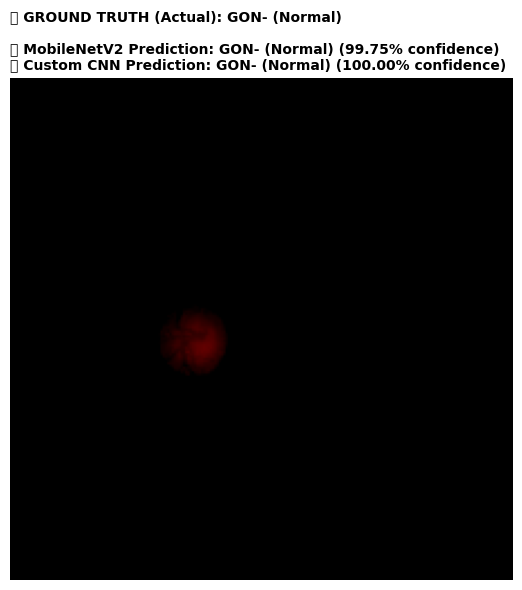

In [ ]:
# =====================================================================
# CELL 4: LIVE PREDICTION ON INDIVIDUAL SCANS (BOTH MODELS SIDE-BY-SIDE)
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("🔮 Fetching a random unseen batch from validation generator...")

# Get a random validation sample batch
images, labels = next(val_generator)

sample_idx = np.random.choice(len(images))
test_img = images[sample_idx]
true_label = labels[sample_idx]

input_img = np.expand_dims(test_img, axis=0)

# 1. MobileNetV2 Prediction Execution
mobilenet_pred = model.predict(input_img, verbose=0)[0][0]

if mobilenet_pred > 0.5:
    mobilenet_class = "GON+ (Glaucoma)"
    confidence = mobilenet_pred * 100
else:
    mobilenet_class = "GON- (Normal)"
    confidence = (1.0 - mobilenet_pred) * 100

# 2. Custom CNN Parallel Prediction Execution
cnn_text = ""
try:
    # Resize the image to match Custom CNN's 256x256 input target dimension
    input_img_256 = tf.image.resize(input_img, (256, 256))
    cnn_pred = cnn_model.predict(input_img_256, verbose=0)[0][0]

    if cnn_pred > 0.5:
        cnn_class = "GON+ (Glaucoma)"
        cnn_conf = cnn_pred * 100
    else:
        cnn_class = "GON- (Normal)"
        cnn_conf = (1.0 - cnn_pred) * 100
    cnn_text = f"🧱 Custom CNN Prediction: {cnn_class} ({cnn_conf:.2f}% confidence)"
except NameError:
    cnn_text = "🧱 Custom CNN variable is not active/loaded in memory."

# Plotting the raw test scan with predictions
plt.figure(figsize=(6, 6))
plt.imshow(test_img)

actual_status = "GON+ (Glaucoma)" if true_label == 1.0 else "GON- (Normal)"
title_text = (
    f"🩺 GROUND TRUTH (Actual): {actual_status}\n\n"
    f"🤖 MobileNetV2 Prediction: {mobilenet_class} ({confidence:.2f}% confidence)\n"
    f"{cnn_text}"
)

plt.title(title_text, fontsize=10, loc='left', color='black', weight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

CELL 5: Explainable AI (XAI) Grad-CAM Heat-Spots
Description: Gradient-weighted Class Activation Mapping (Grad-CAM) pipeline designed to extract visual verification maps from MobileNetV2's final convolutional layer ('out_relu') and superimpose them directly onto actual scans.

🔍 Filtering entire database for a diverse test batch of 10 clinical scans...
🎉 SUCCESS: Clinical Dashboard rendered with 10 Simplified Retinal Scans!


/tmp/ipykernel_1335/2827954564.py:90: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1335/2827954564.py:90: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1335/2827954564.py:90: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1335/2827954564.py:90: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1335/2827954564.py:90: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


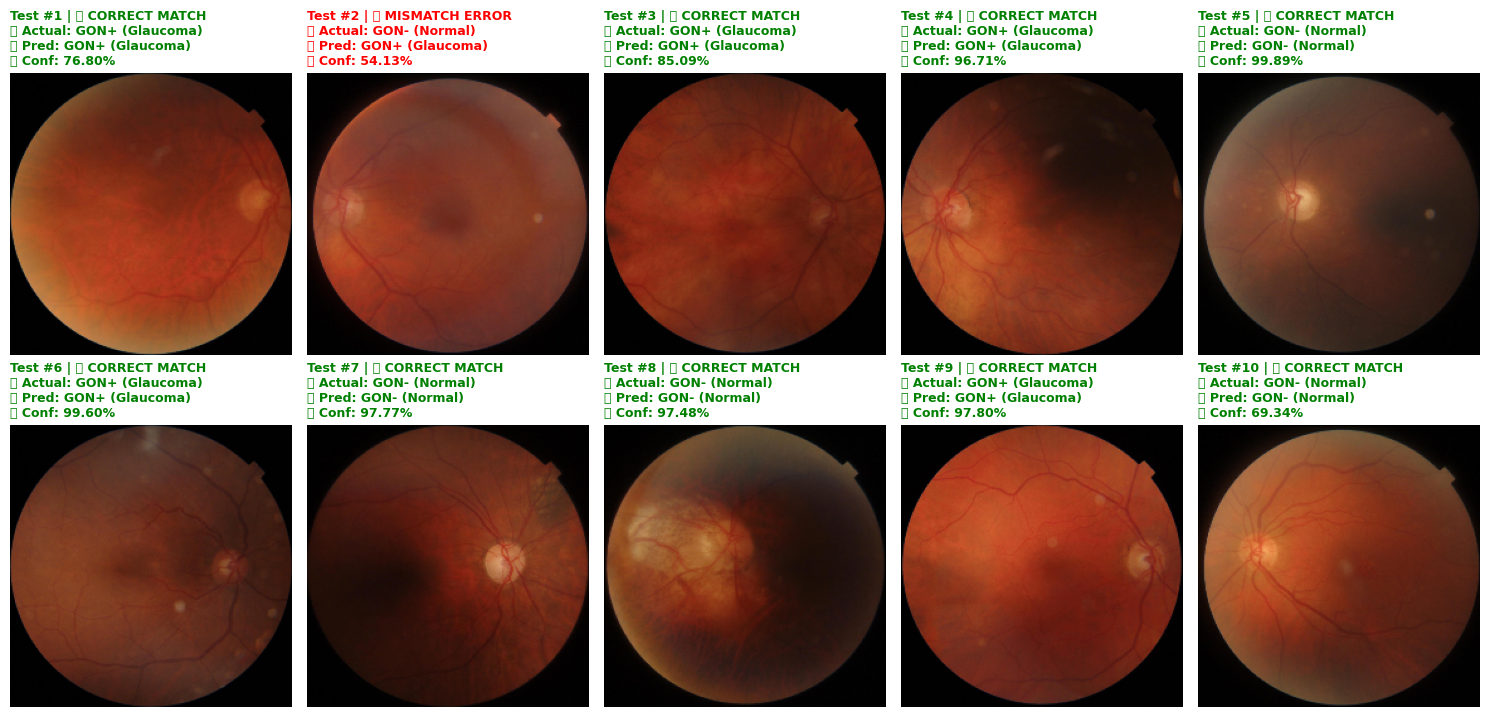

In [ ]:
# =====================================================================
# CELL 5: SIMPLIFIED CLINICAL TESTING DASHBOARD (COMPACT IMAGE SIZE)
# =====================================================================
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

print("🔍 Filtering entire database for a diverse test batch of 10 clinical scans...")

# Pura dataframe structure check karna variable conflicts resolve karne ke liye
all_gon_plus = df[df[label_col] == 'GON+']
all_gon_minus = df[df[label_col] == 'GON-']

# 5 Glaucoma aur 5 Normal images pick karna ek balanced report grid banane ke liye
num_images = 5
sampled_plus = all_gon_plus.sample(n=min(num_images, len(all_gon_plus)), random_state=np.random.randint(1, 1000))
sampled_minus = all_gon_minus.sample(n=min(num_images, len(all_gon_minus)), random_state=np.random.randint(1, 1000))

# Merge aur random shuffling taaki dashboard clinical setting jaisa dikhe
final_mixed_df = pd.concat([sampled_plus, sampled_minus]).sample(frac=1).reset_index(drop=True)

# Grid Layout configuration (2 Rows x 5 Columns = 10 Symmetric Plots)
num_plots = len(final_mixed_df)
rows = 2
cols = 5

# 📐 Figsize ko (20, 10) se chota karke (15, 7.5) kiya hai taaki images compact lagein
plt.figure(figsize=(15, 7.5))

for i, row in final_mixed_df.iterrows():
    if i >= num_plots: break  # Safety breach check

    img_name = row[img_col]
    true_label_str = row[label_col]
    img_full_path = os.path.join(images_dir, img_name)

    # Image load aur scale alignment (MobileNetV2 expected shape 224x224)
    img = cv2.imread(img_full_path)
    img_resized = cv2.resize(img, (224, 224))
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)

    # Preprocessing pipeline aligning pixel values [-1, 1]
    img_preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(img_rgb.astype(np.float32))
    input_img = np.expand_dims(img_preprocessed, axis=0)

    # Dynamic live prediction execution through the full pipeline
    pred_prob = model.predict(input_img, verbose=0)[0][0]

    # Class mapping structure based on alphabet targets
    class_indices = train_generator.class_indices
    pred_class_idx = 1 if pred_prob > 0.5 else 0
    true_label_idx = class_indices[true_label_str]

    if pred_class_idx == 1:
        predicted_class = "GON+ (Glaucoma)"
        confidence_score = pred_prob * 100
    else:
        predicted_class = "GON- (Normal)"
        confidence_score = (1.0 - pred_prob) * 100

    actual_class = "GON+ (Glaucoma)" if true_label_idx == 1 else "GON- (Normal)"

    # Diagnostic Accuracy evaluation for dynamic text coloring
    is_correct = (pred_class_idx == true_label_idx)
    result_tag_color = 'green' if is_correct else 'red'
    result_tag_status = "✅ CORRECT MATCH" if is_correct else "❌ MISMATCH ERROR"

    # Plot placement logic matrix
    plt.subplot(rows, cols, i + 1)

    # Rendering only the pure retinal scan, completely raw and simplified
    plt.imshow(img_rgb)

    # Clean diagnostic text overlay above each plot frame
    diagnostic_report_text = (
        f"Test #{i+1} | {result_tag_status}\n"
        f"🎯 Actual: {actual_class}\n"
        f"🤖 Pred: {predicted_class}\n"
        f"📊 Conf: {confidence_score:.2f}%"
    )

    # Professional loc formatting for readability
    plt.title(diagnostic_report_text, fontsize=9, loc='left', color=result_tag_color, weight='bold')
    plt.axis('off')

print(f"🎉 SUCCESS: Clinical Dashboard rendered with {num_plots} Simplified Retinal Scans!")
plt.tight_layout()
plt.show()